# 02 — Exploratory Data Analysis (FD001)

**Project:** Predictive Intelligence · **Phase 3**

## Objective

Notebook 01 established what the data contains. This notebook looks at how engines *behave* as they wear out, using pictures first and numbers second. It answers:

1. What does wear look like across the whole fleet, not just one engine?
2. How different is a healthy engine from one close to failure?
3. Which sensors tell the same story, and which behave unexpectedly?
4. Is degradation one shared path, or does every engine fail in its own way?

No model is trained here. Every statement below is read from the outputs in this notebook.

> **Data note.** C-MAPSS is simulated turbofan data, not telemetry from real aircraft.

## 1. Setup

In [1]:
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import plotly.graph_objects as go
import plotly.io as pio
import seaborn as sns
from matplotlib.colors import LinearSegmentedColormap
from sklearn.decomposition import PCA

project_root = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "data" / "raw").is_dir())
sys.path.insert(0, str(project_root))

from src.data.cmapss import SENSOR_COLUMNS, SENSOR_INFO, add_training_rul, load_subset
from src.visualization import theme

theme.apply_theme()
pio.renderers.default = "plotly_mimetype+notebook_connected"

train, test, test_rul = load_subset("FD001")
train_labelled = add_training_rul(train)

# Sensors with more than two distinct values (notebook 01 showed the rest are constant).
varying_sensors = [name for name in SENSOR_COLUMNS if train[name].nunique() > 2]


def sensor_label(name: str) -> str:
    return f"{name.replace('sensor_', 'S')} · {SENSOR_INFO[name][0]}"


print(f"{len(varying_sensors)} varying sensors:", ", ".join(sensor_label(s) for s in varying_sensors))

14 varying sensors: S2 · T24, S3 · T30, S4 · T50, S7 · P30, S8 · Nf, S9 · Nc, S11 · Ps30, S12 · phi, S13 · NRf, S14 · NRc, S15 · BPR, S17 · htBleed, S20 · W31, S21 · W32


## 2. Wear across the whole fleet

**The idea.** If we plot a sensor against *cycle number*, engines do not line up: one engine fails at cycle 128, another at 362, so "cycle 150" means end-of-life for one and mid-life for the other. If instead we plot against **cycles remaining before failure**, every engine ends at the same point on the right-hand side, and a shared pattern becomes visible.

A maintenance analogy: comparing patients by "years before the illness was diagnosed" rather than by calendar age.

**Smoothing.** Raw readings are noisy. We replace each reading with the average of the engine's last 15 cycles (a *rolling mean*). This keeps the slow trend and removes most of the flicker. The cost is a small delay: a smoothed line reacts a few cycles late. It uses only past readings, so it would also be available in live operation.

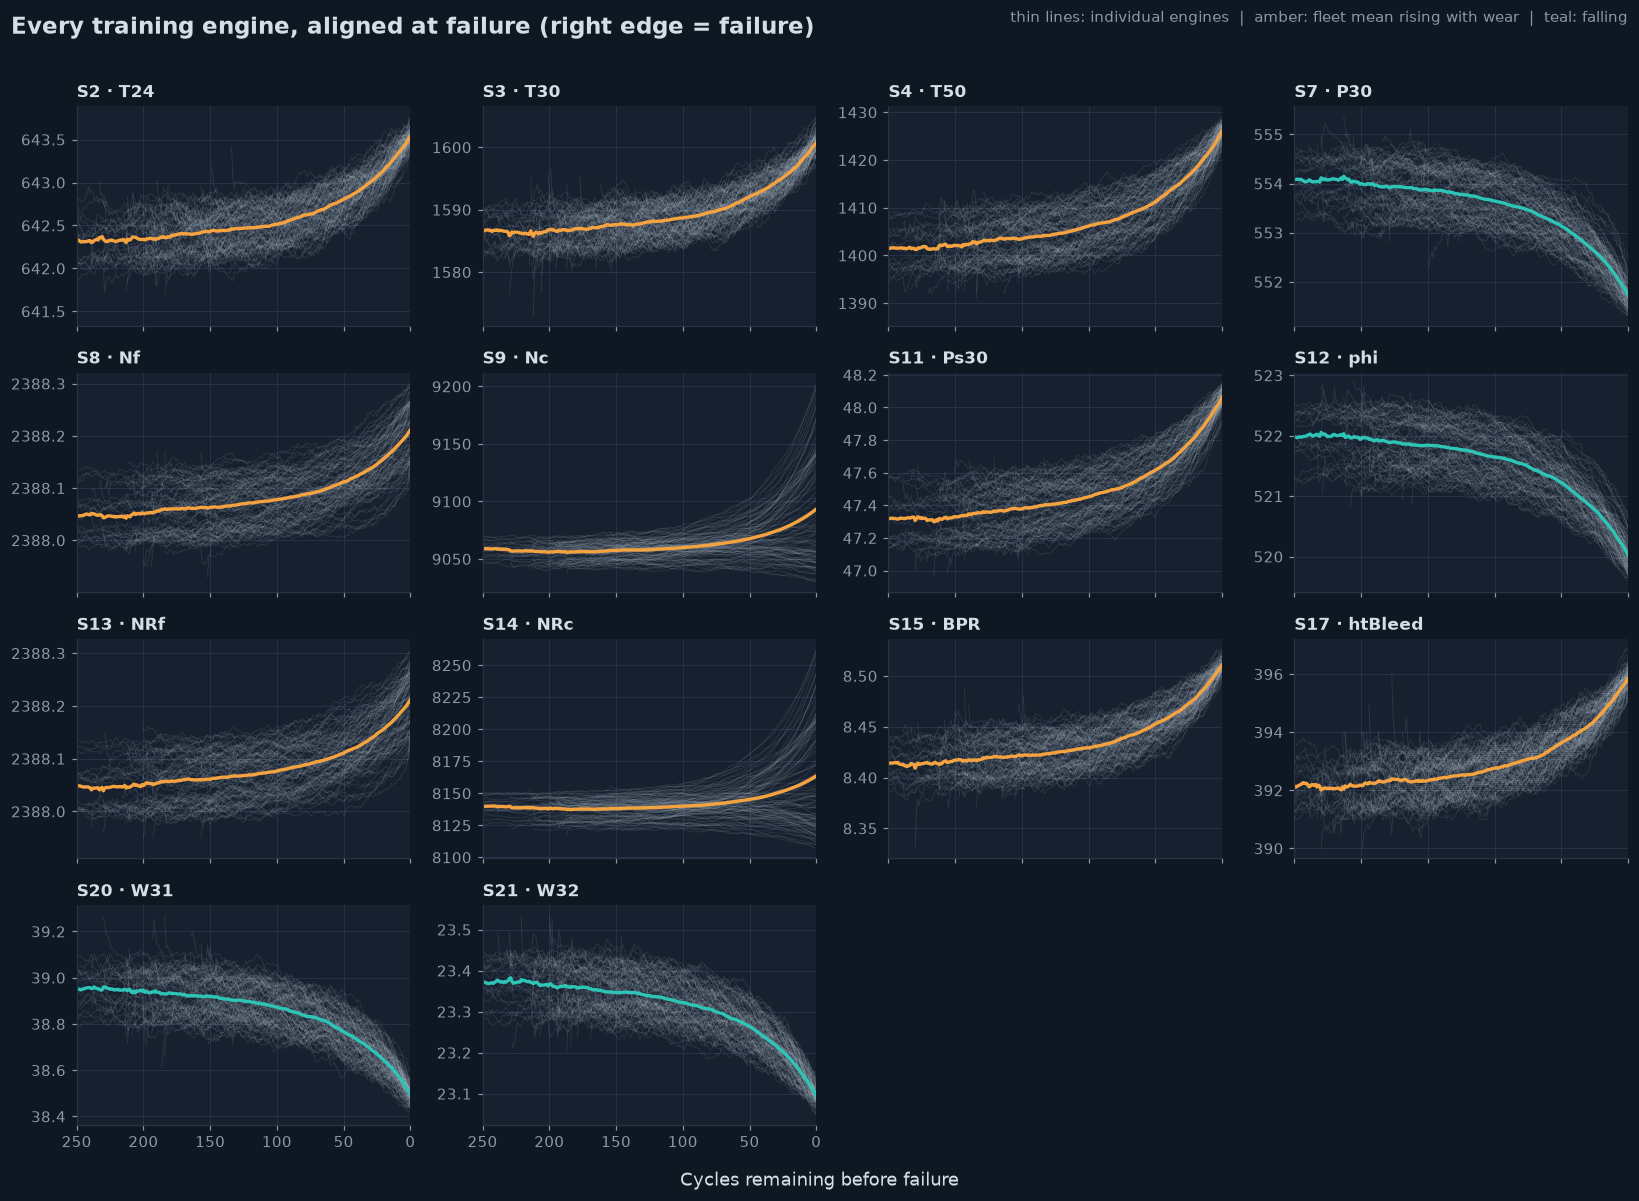

In [2]:
SMOOTHING_WINDOW = 15

smoothed = train_labelled.copy()
smoothed[varying_sensors] = train_labelled.groupby("engine_id")[varying_sensors].transform(
    lambda readings: readings.rolling(SMOOTHING_WINDOW, min_periods=1).mean()
)

# Beyond 250 cycles before failure only a handful of long-lived engines remain,
# so a fleet average out there would describe very few engines.
MAX_RUL_SHOWN = 250
fleet_mean = smoothed[smoothed["rul"] <= MAX_RUL_SHOWN].groupby("rul")[varying_sensors].mean()

fig, axes = plt.subplots(4, 4, figsize=(15, 11), sharex=True)
axes = axes.ravel()

for ax, sensor in zip(axes, varying_sensors):
    for _, engine in smoothed.groupby("engine_id"):
        ax.plot(engine["rul"], engine[sensor], color=theme.SILVER, alpha=0.13, linewidth=0.6)
    rises_with_wear = fleet_mean[sensor].iloc[0] > fleet_mean[sensor].iloc[-1]
    ax.plot(fleet_mean.index, fleet_mean[sensor],
            color=theme.AMBER if rises_with_wear else theme.TEAL, linewidth=2.2)
    ax.set_title(sensor_label(sensor), fontsize=11)
    ax.set_xlim(MAX_RUL_SHOWN, 0)

for ax in axes[len(varying_sensors):]:
    ax.set_visible(False)

fig.suptitle("Every training engine, aligned at failure (right edge = failure)",
             x=0.01, ha="left", fontsize=15, fontweight="bold", color=theme.TEXT)
fig.supxlabel("Cycles remaining before failure", color=theme.TEXT)
fig.text(0.99, 0.985, "thin lines: individual engines  |  amber: fleet mean rising with wear  |  teal: falling",
         ha="right", va="top", color=theme.MUTED, fontsize=10)
fig.tight_layout(rect=(0, 0, 1, 0.97))
plt.show()

In [3]:
checkpoints = [200, 150, 125, 100, 75, 50, 25, 0]
fleet_mean.loc[checkpoints, ["sensor_11", "sensor_4", "sensor_12"]].round(2).T

rul,200,150,125,100,75,50,25,0
sensor_11,47.33,47.38,47.41,47.45,47.51,47.62,47.78,48.06
sensor_4,1402.09,1403.48,1404.49,1406.18,1408.03,1411.23,1416.74,1426.09
sensor_12,521.94,521.85,521.77,521.65,521.49,521.22,520.78,520.03


**What the picture shows.**

- **A shared shape.** Twelve of the fourteen sensors follow the same story: nearly flat while the engine is healthy, then bending away, with the bend getting steeper towards failure. The table makes this concrete for sensor 11 (Ps30): the fleet mean moves by about 0.08 between 200 and 125 cycles before failure, and by about 0.65 over the final 125, eight times as much.
- **Direction is consistent.** Temperatures (S2, S3, S4), static pressure (S11), fan speeds (S8, S13), bypass ratio (S15) and bleed enthalpy (S17) rise with wear. HPC outlet pressure (S7), the fuel-flow ratio (S12) and the two coolant bleeds (S20, S21) fall. This fits a compressor that is losing efficiency: the engine runs hotter and delivers less pressure for the same thrust.
- **Two sensors do not fit the pattern.** The core speeds S9 and S14 fan out instead of following one curve. Section 5 looks at them.
- **The early period carries little information.** More than about 125 cycles before failure, the lines are flat and overlap. A reading taken then looks the same whether the engine has 130 or 300 cycles left.

## 3. Healthy versus close to failure

How far apart are the two ends of an engine's life? We compare readings from each engine's **first 30 cycles** (healthy) with its **last 30 cycles** (close to failure).

To compare sensors that have different units, the shift is expressed in *healthy standard deviations*: how many times the normal healthy scatter the average has moved. A shift of 3 means the typical near-failure reading sits three "noise widths" away from the typical healthy reading.

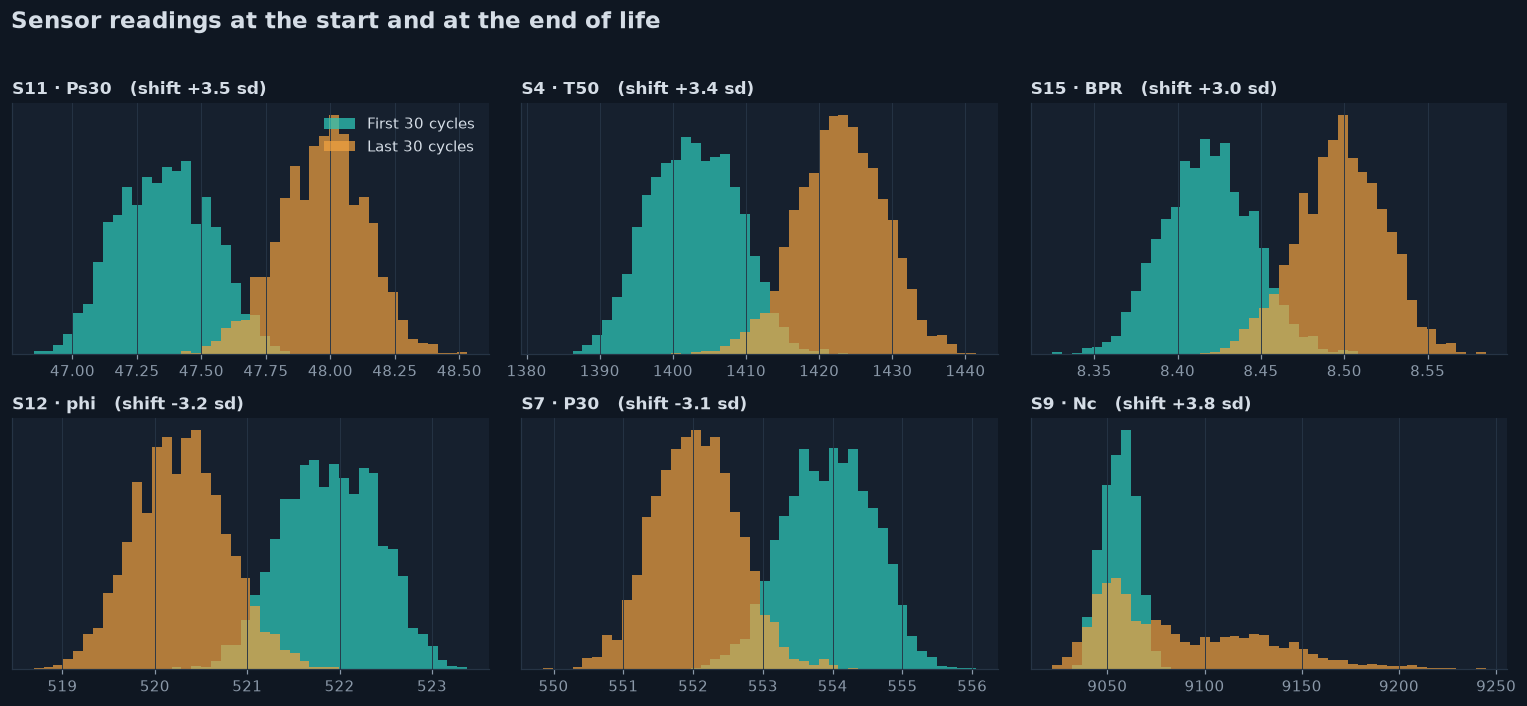

,sensor_12,sensor_7,sensor_20,sensor_21,sensor_8,sensor_13,sensor_3,sensor_2,sensor_17,sensor_14,sensor_15,sensor_4,sensor_11,sensor_9
shift in healthy standard deviations,-3.21,-3.07,-2.91,-2.9,2.37,2.42,2.56,2.63,2.73,2.77,3.01,3.39,3.47,3.75


In [4]:
EDGE_CYCLES = 30
healthy = train_labelled[train_labelled["cycle"] <= EDGE_CYCLES]
near_failure = train_labelled[train_labelled["rul"] < EDGE_CYCLES]

shift = (near_failure[varying_sensors].mean() - healthy[varying_sensors].mean()) / healthy[varying_sensors].std()
shift = shift.sort_values()

sensors_to_compare = ["sensor_11", "sensor_4", "sensor_15", "sensor_12", "sensor_7", "sensor_9"]
fig, axes = plt.subplots(2, 3, figsize=(14, 6.5))
for ax, sensor in zip(axes.ravel(), sensors_to_compare):
    bins = np.linspace(train[sensor].min(), train[sensor].max(), 45)
    ax.hist(healthy[sensor], bins=bins, density=True, color=theme.TEAL, alpha=0.75, label="First 30 cycles")
    ax.hist(near_failure[sensor], bins=bins, density=True, color=theme.AMBER, alpha=0.7, label="Last 30 cycles")
    ax.set_title(f"{sensor_label(sensor)}   (shift {shift[sensor]:+.1f} sd)", fontsize=11)
    ax.set_yticks([])
axes[0, 0].legend(loc="upper right")
fig.suptitle("Sensor readings at the start and at the end of life",
             x=0.01, ha="left", fontsize=15, fontweight="bold", color=theme.TEXT)
fig.tight_layout(rect=(0, 0, 1, 0.96))
plt.show()

shift.round(2).to_frame("shift in healthy standard deviations").T

**Findings.**

- Every varying sensor moves by between roughly 2.4 and 3.8 healthy standard deviations over an engine's life. The two populations are clearly different, which is why RUL prediction on this dataset is feasible at all.
- The histograms still overlap. A single reading from a single sensor cannot reliably say "healthy" or "worn", because sensor noise is of similar size to the early drift. Reliable prediction needs several sensors together and several cycles of history. This is the motivation for sliding windows in Phase 4.
- The near-failure distributions are wider than the healthy ones. Part of that is because the last 30 cycles are themselves a period of rapid change.
- S9 shows the largest average shift but also the widest and most irregular near-failure spread, which again marks it as unusual.

## 4. Which sensors tell the same story?

**Correlation** between two sensors measures how closely they move together, from −1 (perfect opposite) through 0 (unrelated) to +1 (perfectly together). We use the standard (Pearson) correlation here because the question is about straight-line redundancy between sensors.

Why it matters: two sensors with correlation near ±1 carry almost the same information. Some models (linear regression in particular) become unstable when fed near-duplicates, and explanations get muddled because the model can credit either one. Correlation should not be used to conclude that one sensor drives another; here they all respond to the same underlying wear.

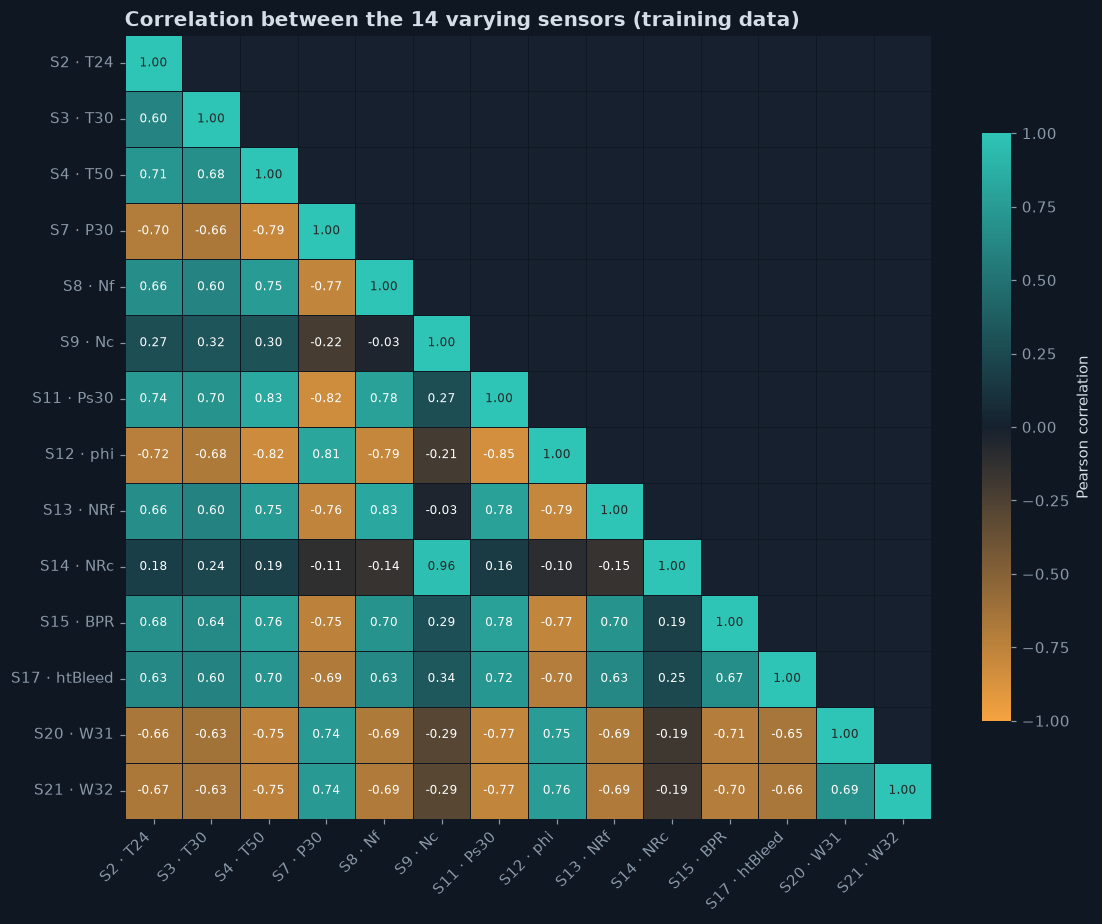

7 of 91 sensor pairs have |correlation| above 0.8


,,correlation
sensor_9,sensor_14,0.963
sensor_11,sensor_12,-0.847
sensor_4,sensor_11,0.830
sensor_8,sensor_13,0.826
sensor_7,sensor_11,-0.823
sensor_4,sensor_12,-0.816
sensor_7,sensor_12,0.813


In [5]:
sensor_correlation = train[varying_sensors].corr()
short_labels = [sensor_label(name) for name in varying_sensors]

diverging = LinearSegmentedColormap.from_list("amber_teal", [theme.AMBER, theme.PANEL, theme.TEAL])
mask_upper = np.triu(np.ones_like(sensor_correlation, dtype=bool), k=1)

fig, ax = plt.subplots(figsize=(10.5, 8.5))
sns.heatmap(sensor_correlation, mask=mask_upper, cmap=diverging, vmin=-1, vmax=1, annot=True, fmt=".2f",
            annot_kws={"size": 8}, linewidths=0.6, linecolor=theme.BACKGROUND,
            xticklabels=short_labels, yticklabels=short_labels,
            cbar_kws={"label": "Pearson correlation", "shrink": 0.75}, ax=ax)
ax.set_title("Correlation between the 14 varying sensors (training data)")
ax.grid(False)
plt.xticks(rotation=45, ha="right")
fig.tight_layout()
plt.show()

pair_values = sensor_correlation.where(mask_upper).stack().dropna().rename("correlation")
strong_pairs = pair_values[pair_values.abs() > 0.8].sort_values(key=abs, ascending=False)
print(f"{len(strong_pairs)} of {len(pair_values)} sensor pairs have |correlation| above 0.8")
strong_pairs.round(3).to_frame()

**Findings.**

- **S9 and S14 (physical and corrected core speed) are nearly the same signal**, with a correlation of 0.96. At a single flight condition the correction changes little, so this is expected.
- **S8 and S13 (physical and corrected fan speed)** are the other physical/corrected pair, at 0.83.
- The remaining strong pairs link the best wear indicators to each other: S11 with S12, S7 and S4; S7 with S12; S4 with S12. They correlate because they all respond to the same degradation, not because one is a copy of another.
- Only 7 of 91 pairs exceed 0.8. Most sensors are related but not interchangeable, because each also carries its own noise.

**Consequence for later phases.** One member of each physical/corrected pair is a candidate for removal, and linear models will need care with collinearity. Both points go to Phase 4 as questions to test, not as decisions.

## 5. The sensors that do not behave: core speed

In section 2, S9 and S14 fanned out instead of following one curve. Here each engine's S9 line is coloured by whether its core speed ended higher or lower than it started. S11 is shown beside it as a well-behaved reference.

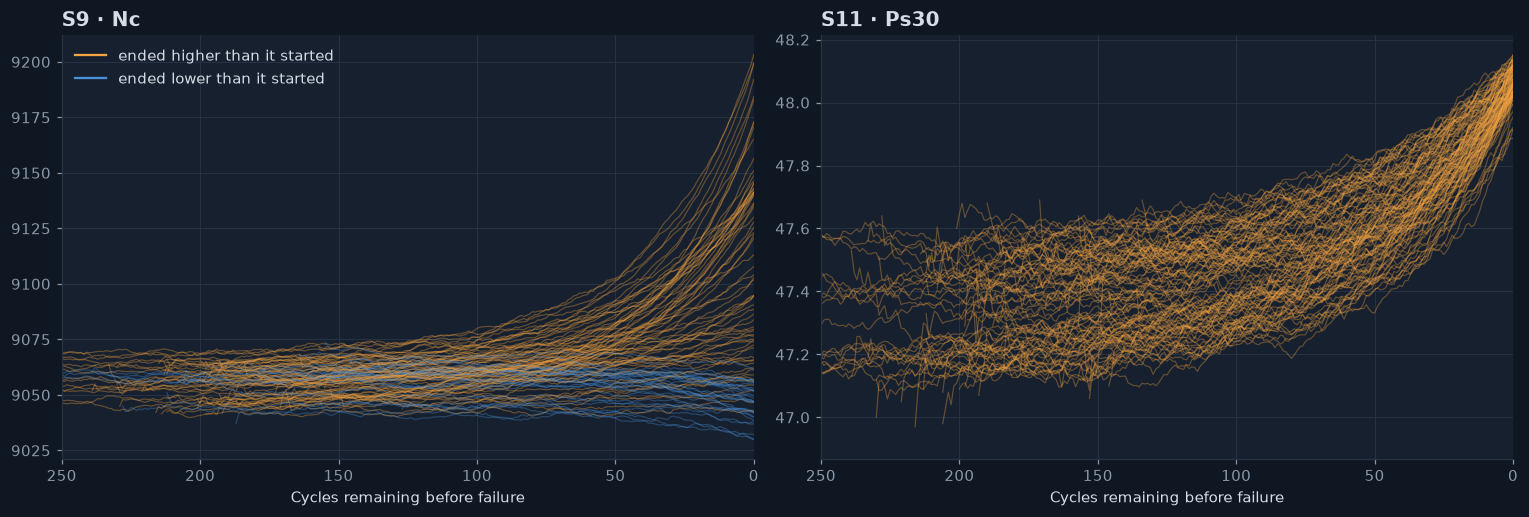

,engines ending higher,engines ending lower,smallest change,largest change
sensor_9,70,30,-21.80,148.06
sensor_11,100,0,0.48,1.05


In [6]:
def change_over_life(readings: pd.Series, edge: int = 10) -> float:
    return readings.iloc[-edge:].mean() - readings.iloc[:edge].mean()


life_change = train.groupby("engine_id")[["sensor_9", "sensor_11"]].agg(change_over_life)

fig, axes = plt.subplots(1, 2, figsize=(14, 4.8), sharex=True)
for ax, sensor in zip(axes, ["sensor_9", "sensor_11"]):
    for engine_id, engine in smoothed.groupby("engine_id"):
        went_up = life_change.loc[engine_id, sensor] > 0
        ax.plot(engine["rul"], engine[sensor], color=theme.AMBER if went_up else theme.BLUE,
                alpha=0.35, linewidth=0.8)
    ax.set_xlim(MAX_RUL_SHOWN, 0)
    ax.set_title(sensor_label(sensor))
    ax.set_xlabel("Cycles remaining before failure")
axes[0].plot([], [], color=theme.AMBER, label="ended higher than it started")
axes[0].plot([], [], color=theme.BLUE, label="ended lower than it started")
axes[0].legend(loc="upper left")
fig.tight_layout()
plt.show()

summary = pd.DataFrame({
    "engines ending higher": (life_change > 0).sum(),
    "engines ending lower": (life_change < 0).sum(),
    "smallest change": life_change.min().round(2),
    "largest change": life_change.max().round(2),
})
summary

**Findings.**

- For S11, all 100 engines end higher than they start. The direction of change is reliable.
- For S9, the engines split: most end with a higher core speed, some by well over 100 rpm, while a sizeable minority end slightly *lower*. The size of the change also varies enormously between engines.
- So the same sensor reading can mean different things on different engines. A high core speed is a strong sign of wear on some engines and absent on others.

**Why this matters.** A model can still use S9 and S14, but they are less trustworthy as general indicators, and this is exactly the kind of sensor an explanation method should be checked against in Phase 7. We do not know the mechanical reason from the data alone. A plausible cause is the engine control system adjusting core speed to hold thrust as different engines degrade differently, but that is a hypothesis, not a finding.

## 6. Short-lived and long-lived engines

Do engines that fail early wear out in a different way, or just faster? We take the shortest-lived engine, the longest-lived one, and one with a typical life, and plot the same sensor two ways.

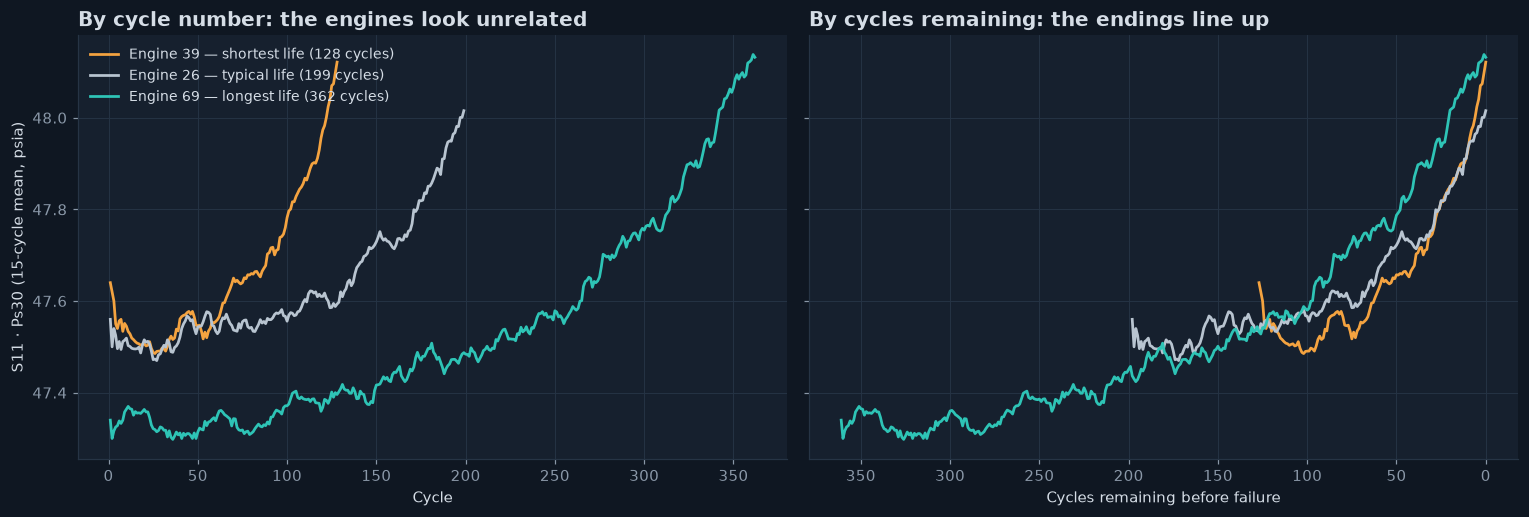

In [7]:
engine_life = train.groupby("engine_id")["cycle"].max()
selected_engines = {
    "shortest life": engine_life.idxmin(),
    "typical life": (engine_life - engine_life.median()).abs().idxmin(),
    "longest life": engine_life.idxmax(),
}
line_colors = [theme.AMBER, theme.SILVER, theme.TEAL]

fig, axes = plt.subplots(1, 2, figsize=(14, 4.8), sharey=True)
for (description, engine_id), color in zip(selected_engines.items(), line_colors):
    engine = smoothed[smoothed["engine_id"] == engine_id]
    label = f"Engine {engine_id} — {description} ({engine_life[engine_id]} cycles)"
    axes[0].plot(engine["cycle"], engine["sensor_11"], color=color, linewidth=1.8, label=label)
    axes[1].plot(engine["rul"], engine["sensor_11"], color=color, linewidth=1.8)

axes[0].set_title("By cycle number: the engines look unrelated")
axes[0].set_xlabel("Cycle")
axes[0].set_ylabel(f"{sensor_label('sensor_11')} (15-cycle mean, psia)")
axes[0].legend(loc="upper left", fontsize=9)
axes[1].set_title("By cycles remaining: the endings line up")
axes[1].set_xlabel("Cycles remaining before failure")
axes[1].invert_xaxis()
fig.tight_layout()
plt.show()

**Findings.**

- Plotted by cycle number (left), the three engines look like three different stories. Knowing only "this engine is at cycle 150" tells us very little about its health.
- Plotted by cycles remaining (right), the final stretch of all three follows a similar climb to a similar end level. The long-lived engine is not wearing in a different way; it simply spends much longer in the flat, healthy phase before the same decline begins.
- This is the central reason the model's input should be the **sensor readings**, not the engine's age. Age alone would predict that every engine fails at the fleet average.

## 7. Degradation as a path through sensor space

So far each chart showed one sensor at a time. An engine's condition at any moment is really a *combination* of readings. If we take three sensors that measure different physical things and use them as the three axes of a 3D chart, each engine traces a path through that space as it ages.

We use a temperature (S4, T50), a pressure (S11, Ps30) and the fuel-flow ratio (S12, phi). Three dimensions earn their place here because the question is about the *shape* of the path: do engines scatter in all directions, or travel along one shared route? That cannot be read from separate 2D charts.

The chart is interactive: drag to rotate, scroll to zoom, hover for values. Colour shows cycles remaining, from teal (healthy) to amber (close to failure).

In [8]:
axis_sensors = ["sensor_4", "sensor_11", "sensor_12"]

# Six engines spread evenly across the range of lifetimes, from shortest to longest.
ranked_engines = engine_life.sort_values().index
engines_to_trace = ranked_engines[np.linspace(0, len(ranked_engines) - 1, 6).astype(int)]

rul_colorscale = [[0.0, theme.RED], [0.25, theme.AMBER], [0.6, theme.BLUE], [1.0, theme.TEAL]]
colour_limit = 200  # cap the colour range so the last 200 cycles use the full scale

fig = go.Figure()
for position, engine_id in enumerate(engines_to_trace):
    engine = smoothed[smoothed["engine_id"] == engine_id]
    fig.add_trace(go.Scatter3d(
        x=engine[axis_sensors[0]], y=engine[axis_sensors[1]], z=engine[axis_sensors[2]],
        mode="lines",
        line=dict(width=5, color=engine["rul"].clip(upper=colour_limit), colorscale=rul_colorscale,
                  cmin=0, cmax=colour_limit, showscale=(position == 0),
                  colorbar=dict(title="Cycles<br>remaining", thickness=14, len=0.6)),
        name=f"Engine {engine_id} ({engine_life[engine_id]} cycles)",
        customdata=np.stack([engine["cycle"], engine["rul"]], axis=1),
        hovertemplate=(f"Engine {engine_id}<br>cycle %{{customdata[0]}} · %{{customdata[1]}} remaining"
                       "<br>T50 %{x:.1f} · Ps30 %{y:.2f} · phi %{z:.2f}<extra></extra>"),
    ))
    last = engine.iloc[-1]
    fig.add_trace(go.Scatter3d(
        x=[last[axis_sensors[0]]], y=[last[axis_sensors[1]]], z=[last[axis_sensors[2]]],
        mode="markers", marker=dict(size=5, color=theme.RED, symbol="x"),
        showlegend=(position == 0), name="Failure point", hoverinfo="skip",
    ))

axis_style = dict(backgroundcolor=theme.PANEL, gridcolor=theme.GRID, zerolinecolor=theme.GRID, color=theme.TEXT)
fig.update_layout(
    title="Six engines travelling from healthy to failure (15-cycle rolling means)",
    height=640,
    scene=dict(
        xaxis=dict(title="S4 · T50 (°R)", **axis_style),
        yaxis=dict(title="S11 · Ps30 (psia)", **axis_style),
        zaxis=dict(title="S12 · phi (pps/psi)", **axis_style),
        camera=dict(eye=dict(x=1.6, y=-1.5, z=0.9)),
    ),
    legend=dict(x=0.0, y=0.98, font=dict(size=11)),
    margin=dict(l=0, r=0, t=60, b=0),
)
fig.show()

### Checking the impression with numbers

A 3D picture can mislead, so we test the same idea on all 100 engines and all 14 sensors using **Principal Component Analysis (PCA)**.

In plain terms: PCA looks at a cloud of points in many dimensions and finds the single direction along which the points are most spread out, then the next most, and so on. If one direction accounts for most of the spread, the data is essentially lying along a line, even though it was measured with 14 sensors.

Sensors are first put on a common scale (subtract the mean, divide by the standard deviation), otherwise a sensor measured in thousands of rpm would dominate one measured in single digits. PCA is appropriate for finding shared straight-line structure; it would miss structure that is strongly curved, and its directions are mathematical mixtures of sensors, not physical quantities.

In [9]:
standardised = (train[varying_sensors] - train[varying_sensors].mean()) / train[varying_sensors].std()
pca = PCA().fit(standardised)

explained = pd.Series(pca.explained_variance_ratio_, index=[f"PC{i}" for i in range(1, len(varying_sensors) + 1)])
first_component = pd.Series(pca.transform(standardised)[:, 0], index=train.index)

print("Share of total variation captured by each direction:")
print(explained.head(5).mul(100).round(1).astype(str).add(" %").to_string())
print(f"\nSpearman correlation between the first direction and RUL: "
      f"{first_component.corr(train_labelled['rul'], method='spearman'):+.2f}")

loadings = pd.Series(pca.components_[1], index=[sensor_label(s) for s in varying_sensors])
print("\nSensors with the largest weight in the second direction:")
print(loadings.abs().sort_values(ascending=False).head(3).round(2).to_string())

Share of total variation captured by each direction:
PC1    64.3 %
PC2    15.0 %
PC3     3.0 %
PC4     2.6 %
PC5     2.5 %

Spearman correlation between the first direction and RUL: -0.76

Sensors with the largest weight in the second direction:
S14 · NRc    0.67
S9 · Nc      0.64
S13 · NRf    0.25


**Findings.**

- In the 3D chart the six engines start in the same region and move the same way: T50 and Ps30 rise while phi falls. They do not wander off in separate directions.
- PCA confirms this across the whole fleet. A single direction captures about 64% of all variation in the 14 sensors, and it tracks remaining life closely (Spearman correlation of −0.76 with RUL). This is the shared wear path.
- The second direction adds about 15% and is made up almost entirely of the two core speeds, S14 and S9. In other words, the main thing that distinguishes engines *apart from* how worn they are is the core-speed behaviour from section 5. PCA found the same oddity independently.
- So FD001 behaves largely like a **one-dimensional wear process observed through many noisy sensors**. That fits how the data was made: one fault mode, one flight condition.

**What this means and does not mean.** It explains why fairly simple models are known to do reasonably well on FD001, and it sets an honest expectation that a complex deep network may add less here than on harder subsets. It does not mean one sensor is enough: combining sensors averages out their independent noise. And it will not carry over to FD003 and FD004, which have a second fault mode.

## 8. Conclusions

| Question | What we found |
|---|---|
| What does fleet-wide wear look like? | Flat while healthy, then accelerating drift, most visible in roughly the last 125 cycles |
| How different are healthy and near-failure readings? | 2.4 to 3.8 healthy standard deviations apart on every varying sensor, but single readings overlap |
| Which sensors are redundant? | S9/S14 (0.96) and S8/S13 (0.83) are physical/corrected pairs; 7 of 91 pairs exceed 0.8 |
| Which sensors misbehave? | Core speeds S9 and S14: direction and size of change differ from engine to engine |
| Short versus long-lived engines? | Same ending, different length of healthy phase; age alone is a poor health indicator |
| One path or many? | Largely one: a single direction holds about 64% of the variation |

**Limitations.** These are observations on 100 simulated engines with one fault mode at one flight condition. The patterns are cleaner than real fleet data would be. Correlation and PCA describe association, not mechanical cause.

## 9. Next steps

1. **Notebook 03 — Statistical analysis:** test formally when a sensor's drift becomes distinguishable from noise, check the distributions, and quantify monotonic trend per sensor.
2. Questions carried to Phase 4: drop one of each physical/corrected pair? keep or drop S9/S14? cap RUL near the point where drift becomes visible? how many cycles should a window contain?